# Model Setup and Fine Tuning - Dzifa Thomas

## RoBERTa Model Setup and Initial Training

## 1. Load and Inspect the Prepared Dataset

### Load the tokenized Hugging Face datasets prepared in Task #1 - Milestone 2 for multi-label classification across 41 legal clause catergories

In [1]:
from datasets import load_from_disk
from transformers import AutoTokenizer, DataCollatorWithPadding

ds = load_from_disk("../data/processed/roberta_dataset")   # run this notebook first
train_ds, val_ds, test_ds = ds["train"], ds["validation"], ds["test"]

tokenizer = AutoTokenizer.from_pretrained("roberta-base")
collator = DataCollatorWithPadding(tokenizer) 

/Users/dzifathomas/Documents/GitHub/Accenture-1H-contract-review-challenge/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Initialize RoBERTa for Multi-label Classification

Load the pretrained RoBERTa-base model and configure it to predict 41 legal clause categories.

In [2]:
from transformers import AutoModelForSequenceClassification

NUM_LABELS = 41

model = AutoModelForSequenceClassification.from_pretrained("roberta-base", num_labels = NUM_LABELS, problem_type = "multi_label_classification")

W1018 23:43:22.527000 88508 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 7808.48it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstr

In [3]:
# Verify the model
print("Model:", model.config.model_type)
print("Number of labels:", model.config.num_labels)
print("Problem type:", model.config.problem_type)

Model: roberta
Number of labels: 41
Problem type: multi_label_classification


## 3. Configure the Training Pipeline

In [4]:
# Verify Dataset Compatibility
# Check that the prepared dataset contains the correct label format for multi-label classification.
import torch

print("Dataset columns:", train_ds.column_names)
print("Number of labels:", len(train_ds[0]["labels"]))
print("Label example:", train_ds[0]["labels"])
print("Label feature:", train_ds.features["labels"])


Dataset columns: ['title', 'chunk_id', 'labels', 'input_ids', 'attention_mask']
Number of labels: 41
Label example: [0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Label feature: List(Value('float32'), length=41)


In [5]:
# Prepare model outputs: Remove metadata columns that are not required by RoBERTa.
# Keep the token IDs, attention masks, and 41-label vectors.

model_columns = ["input_ids", "attention_mask", "labels"]

train_model_ds = train_ds.select_columns(model_columns)
val_model_ds = val_ds.select_columns(model_columns)

print("Training columns:", train_model_ds.column_names)
print("Validation columns:", val_model_ds.column_names)


Training columns: ['input_ids', 'attention_mask', 'labels']
Validation columns: ['input_ids', 'attention_mask', 'labels']


In [6]:
# Configure training arguements 
# Define the settings for a small initial training run to verify that the RoBERTa fine-tuning pipeline works correctly.

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="../models/roberta_initial",
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    max_steps=50,
    learning_rate=2e-5,
    logging_steps=1,
    save_strategy="no",
    eval_strategy="no",
    report_to="none",
    use_cpu=True
)

print("Training arguments configured successfully!")


Training arguments configured successfully!


In [7]:
# Initialize the Hugging Face Trainer
# Connect the RoBERTa model, training arguments, prepared datasets, and data collator to create the fine-tuning pipeline


from transformers import Trainer

# Small subset for initial testing
small_train_ds = train_model_ds.select(range(64))

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=small_train_ds,
    eval_dataset=val_model_ds,
    data_collator=collator
)

print("Trainer initialized successfully!")


Trainer initialized successfully!


In [8]:
# Test the collator

batch = collator([small_train_ds[0]])

print("Input shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)
print("Labels dtype:", batch["labels"].dtype)


Input shape: torch.Size([1, 505])
Attention mask shape: torch.Size([1, 505])
Labels shape: torch.Size([1, 41])
Labels dtype: torch.float32


In [9]:
#Run Initial Training
#Run a five-step training test to verify that the model can calculate loss, perform backpropagation, and update its weights.


# Run the initial fine-tuning test
train_result = trainer.train()

# Display training results
print("Training completed successfully!")
print("Training loss:", train_result.training_loss)
print("Training steps:", train_result.global_step)


Step,Training Loss
1,0.685791
2,0.679015
3,0.678986
4,0.674518
5,0.660257
6,0.637230
7,0.623259
8,0.571903
9,0.567007
10,0.561146


Training completed successfully!
Training loss: 0.4781811410188675
Training steps: 50


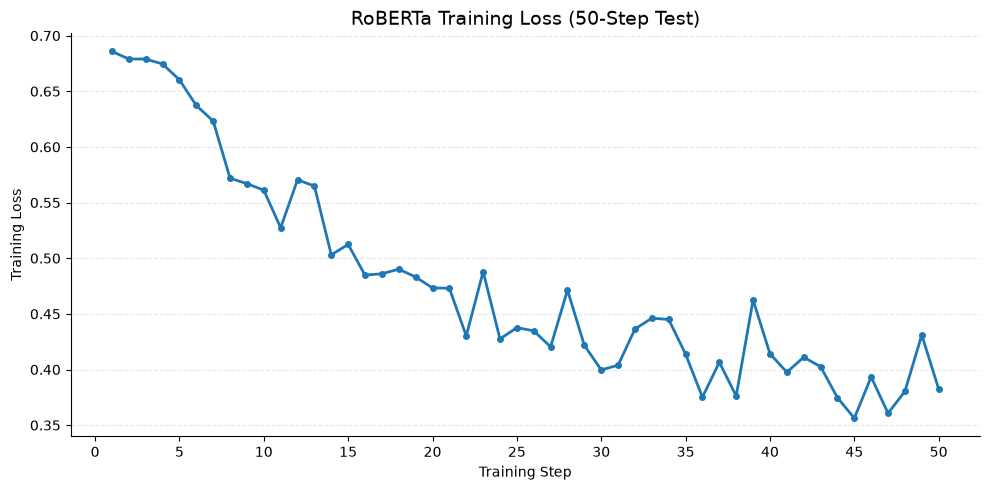

In [10]:

import matplotlib.pyplot as plt

# Extract training loss from Trainer logs
loss_logs = [
    log for log in trainer.state.log_history
    if "loss" in log
]

steps = [log["step"] for log in loss_logs]
losses = [log["loss"] for log in loss_logs]

# Plot training loss
plt.figure(figsize=(10, 5))

plt.plot(steps, losses, marker="o", markersize=4, linewidth=2)

plt.xlabel("Training Step")
plt.ylabel("Training Loss")
plt.title("RoBERTa Training Loss (50-Step Test)", fontsize=14)

# Show X-axis labels every 5 steps
plt.xticks(range(0, 51, 5))

# Light horizontal grid only
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Remove unnecessary borders
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



The training loss decreased from approximately 0.69 to 0.38 over 50 steps, with some fluctuations. This indicates that the model is reducing its training loss and that the fine-tuning pipeline is functioning correctly. However, further training and validation are needed to evaluate classification performance.